# Informed (Heuristic) Search

**Agenda**

1. Recap and basic concepts: heuristics, best-first search
2. Greedy Best-First Search
3. Beam Search
4. Hill Climbing
5. Heuristics: admissible and consistent heuristics, the 8-puzzle, relaxed problems, dominance
6. A* Search
7. Iterative Deepening A* (IDA*)
8. Summary of the algorithms

## Setup: imports and helper code

The helpers are the same as last time, with a few additions: directed graphs, heuristic values written next
to every node, the found path drawn in orange, and nodes thrown away by beam search drawn in dark gray.

You do not need to understand the code. The algorithms in the next sections are what matters.

In [1]:
# The imports used in the rest of the notebook
import heapq

import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.lines import Line2D

In [2]:
# Helper code that can be skipped

def make_undirected(edges):
    graph = {}
    for u, v, cost in edges:
        graph.setdefault(u, []).append((v, cost))
        graph.setdefault(v, []).append((u, cost))
    for node in graph:
        graph[node].sort()                    # children in alphabetical order
    return graph


def make_directed(edges):
    graph = {}
    for u, v, cost in edges:
        graph.setdefault(u, []).append((v, cost))   # children in the order the edges are listed
        graph.setdefault(v, [])
    return graph


def tree_layout(graph, root):
    positions = {}
    next_leaf_x = [0]                         # a list so the inner function can modify it

    def place(node, depth):
        kids = [kid for kid, _ in graph[node]]
        if not kids:
            positions[node] = (next_leaf_x[0], -depth)
            next_leaf_x[0] += 1
        else:
            for kid in kids:
                place(kid, depth + 1)
            xs = [positions[kid][0] for kid in kids]
            positions[node] = (sum(xs) / len(xs), -depth)   # parent centred above its children

    place(root, 0)
    return positions


def reconstruct_path(parent, goal):
    path = [goal]
    while parent[path[-1]] is not None:
        path.append(parent[path[-1]])
    return path[::-1]


def path_cost(graph, path):
    costs = {(u, v): c for u in graph for v, c in graph[u]}
    return sum(costs[(u, v)] for u, v in zip(path, path[1:]))


def format_result(path, cost, expanded):
    route = " -> ".join(map(str, path)) if path else "no path found"
    return f"path: {route} (cost {cost}) | expanded: {' '.join(map(str, expanded))}"


def draw_graph(graph, positions, h=None, path=None, expanded=(), visited=(), pruned=(), goals=(), title="",
               directed=False, show_weights=True, labels=None, node_size=800, figsize=(9, 5), show_legend=True):
    path_edges = set(zip(path, path[1:])) if path else set()
    if not directed:
        path_edges |= {(v, u) for u, v in path_edges}

    nx_graph = nx.DiGraph() if directed else nx.Graph()
    for u, neighbours in graph.items():
        nx_graph.add_node(u)
        for v, cost in neighbours:
            nx_graph.add_edge(u, v, weight=cost)
    nodes = list(nx_graph.nodes)
    edges = list(nx_graph.edges)

    fills = ["#c0504d" if n in expanded else "#555555" if n in pruned else "#4f81bd" if n in visited
             else "white" for n in nodes]
    fig, ax = plt.subplots(figsize=figsize)
    arrow_options = {"arrows": True, "arrowsize": 16} if directed else {"arrows": False}
    nx.draw_networkx_edges(nx_graph, positions, ax=ax, edgelist=edges, node_size=node_size, **arrow_options,
                           width=[4 if e in path_edges else 1.5 for e in edges],
                           edge_color=["orange" if e in path_edges else "gray" for e in edges])
    nx.draw_networkx_nodes(nx_graph, positions, ax=ax, nodelist=nodes, node_size=node_size, node_color=fills,
                           edgecolors=["green" if n in goals else "black" for n in nodes],
                           linewidths=[4 if n in goals else 1.2 for n in nodes])
    for node in nodes:
        x, y = positions[node]
        text = labels[node] if labels else node
        colour = "white" if node in expanded or node in pruned or node in visited else "black"
        ax.text(x, y, str(text), ha="center", va="center", fontsize=10, fontweight="bold", color=colour)
        if h is not None:
            ax.annotate(f"({h[node]})", (x, y), xytext=(14, 14), textcoords="offset points",
                        fontsize=9, fontweight="bold")
    if show_weights:
        edge_labels = {(u, v): data["weight"] for u, v, data in nx_graph.edges(data=True)}
        nx.draw_networkx_edge_labels(nx_graph, positions, edge_labels=edge_labels, ax=ax, font_size=9)
    if show_legend and expanded:
        legend = [("white", "node"), ("#4f81bd", "visited"), ("#c0504d", "expanded"), ("#555555", "pruned")]
        handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=colour, markeredgecolor="black",
                          markersize=12, label=label) for colour, label in legend]
        handles.append(Line2D([0], [0], color="orange", linewidth=4, label="path found"))
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
    ax.set_title(title)
    ax.margins(0.08)
    ax.axis("off")
    fig.tight_layout()
    return fig

def add_mountain(fig):
    ax = fig.axes[0]
    ax.fill([1.3, 2.1, 2.6, 3.1, 3.7], [2.5, 3.5, 3.0, 3.4, 2.5], color="lightgray", zorder=0)
    ax.text(2.5, 2.7, "mountain", ha="center", color="gray", zorder=0)
    return fig


def draw_puzzle(ax, state, title="", highlighted=(), corner_labels=None):
    size = round(len(state) ** 0.5)
    for index, tile in enumerate(state):
        row, col = divmod(index, size)
        x, y = col, size - 1 - row                       # row 0 is drawn at the top
        if tile == 0:
            ax.add_patch(plt.Rectangle((x, y), 1, 1, facecolor="#e6e6e6", edgecolor="#e6e6e6"))
            continue
        colour = "#f4b6b6" if tile in highlighted else "#dbe7f3"
        ax.add_patch(plt.Rectangle((x + 0.05, y + 0.05), 0.9, 0.9, facecolor=colour, edgecolor="black",
                                   linewidth=1.5))
        ax.text(x + 0.5, y + 0.5, str(tile), ha="center", va="center", fontsize=22, fontweight="bold")
        if corner_labels and tile in corner_labels:
            ax.text(x + 0.88, y + 0.12, corner_labels[tile], ha="right", va="bottom", fontsize=10,
                    color="#c0504d", fontweight="bold")
    ax.add_patch(plt.Rectangle((0, 0), size, size, fill=False, edgecolor="black", linewidth=3))
    ax.set_xlim(-0.05, size + 0.05)
    ax.set_ylim(-0.05, size + 0.05)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)

---

# 1. Recap and basic concepts

## 1.1 Uninformed vs informed search

- **Uninformed Search**: uses **only the information available in the problem definition** - the
  connections between states and the costs of the edges.
    - Examples: DFS, BFS, UCS, DLS, IDS.
- **Informed Search**: has extra information about where the goal is, which helps it search more
  efficiently. This information comes from a function (a **heuristic**) that estimates how close a state
  is to the goal state.
    - Examples: Greedy Best-First Search, Beam Search, Hill Climbing, A*, IDA*.

Remember UCS: it expands nodes in order of the cost **already paid**, $g(n)$, in every direction equally - it
has no idea where the goal is. Informed search adds an estimate of the cost **still to pay**.

## 1.2 Heuristics

> A **heuristic** $h(n)$ is a function that **estimates the cost (or distance) from a state $n$ to a goal state**.
> It gives problem-specific guidance to the search algorithm, so it prefers the more promising states.

- It takes a state as input and returns a number - an **estimate** of the remaining cost until we reach the goal.
- $h(n)$ is an **estimate**, not the true cost. The true cost of the cheapest path from $n$ to a goal is written $h^*(n)$, and it is generally **unknown**.
- If we knew $h^*$ exactly, we would not need to search at all - we would just always follow the neighbour of the current state $n$ with
  the smallest $c(n, n') + h^*(n')$, where $c(n, n')$ is the cost of the edge between nodes $n$ and $n'$, but of course, we do not know $h^*(n)$, so we cannot do this.
- $h(n)$ must be **cheap to compute** - it is evaluated for every generated node.
- By convention $h(n) \ge 0$, and $h(G) = 0$ for every goal $G$.

Examples:

| Problem | Heuristic $h(n)$ |
|---|---|
| Route finding on a road map | straight-line (Euclidean) distance from the city $n$ to the goal city, $h_{SLD}$ |
| Moving on a grid (up / down / left / right) | Manhattan distance $\lvert x - x_G \rvert + \lvert y - y_G \rvert$ |
| 8-puzzle | number of misplaced tiles, or sum of the Manhattan distances of all tiles (section 5.3) |

## 1.3 Best-First Search

- **Idea**: use an **evaluation function $f(n)$** for every node - an estimate of how "desirable" it is -
  and always **expand the most desirable unexpanded node**.
- **Implementation**: the frontier is a **priority queue** ordered by $f(n)$, exactly like in UCS.

Everything is the same loop with a different $f$, or with a limit on how big the frontier may grow:

| Algorithm | Evaluation function $f(n)$ | Frontier |
|---|---|---|
| UCS (last week) | $g(n)$ - cost so far | priority queue |
| Greedy Best-First Search | $h(n)$ - estimated cost to the goal | priority queue |
| Beam Search | $h(n)$ | priority queue that keeps only the best $l$ nodes |
| Hill Climbing | $h(n)$ | priority queue that keeps only the single best node (Beam Search with $l = 1$) |
| A* | $g(n) + h(n)$ - estimated total cost of a path through $n$ | priority queue |
| IDA* | $g(n) + h(n)$, used as a threshold | stack (it is a type of DFS) |

So the informed algorithms form two families:

- Use only the heuristic: **Greedy** → Beam Search → Hill Climbing
- Use the heuristic and the current cost: **A*** → Iterative Deepening A* (IDA*)

## 1.4 The graphs we use today

1. **The lecture graph** - undirected, start S, goal G. The number in brackets next to every node is its
   heuristic value $h(n)$.
2. **The class notes graph** - directed, start S, goal G, with its own heuristic.

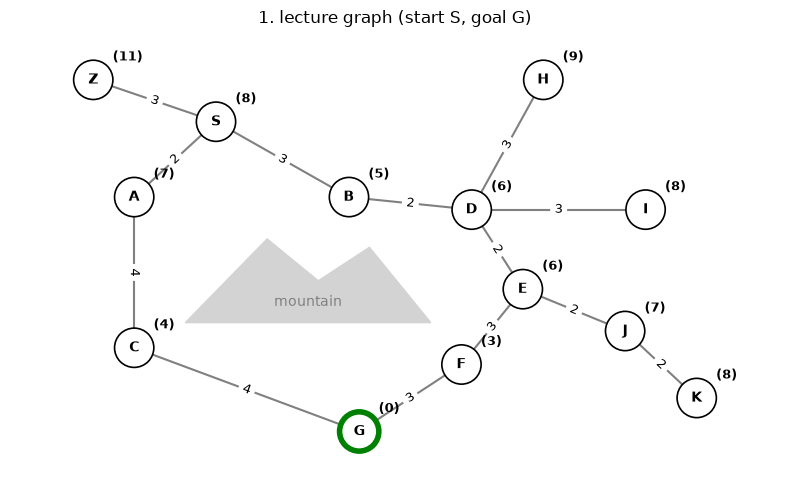

In [3]:
lecture_graph = make_undirected([
    ("Z", "S", 3), ("S", "A", 2), ("S", "B", 3), ("A", "C", 4), ("B", "D", 2), ("C", "G", 4),
    ("D", "E", 2), ("D", "H", 3), ("D", "I", 3), ("E", "J", 2), ("E", "F", 3), ("F", "G", 3), ("J", "K", 2),
])

# The heuristic values
lecture_h = {"Z": 11, "S": 8, "A": 7, "B": 5, "C": 4, "D": 6, "E": 6, "F": 3, "G": 0,
             "H": 9, "I": 8, "J": 7, "K": 8}
lecture_pos = {
    "Z": (0.4, 5.4), "S": (1.6, 4.9), "A": (0.8, 4.0), "B": (2.9, 4.0), "C": (0.8, 2.2), "D": (4.1, 3.85),
    "H": (4.8, 5.4), "I": (5.8, 3.85), "E": (4.6, 2.9), "J": (5.6, 2.4), "K": (6.3, 1.6), "F": (4.0, 2.0),
    "G": (3.0, 1.2),
}

add_mountain(draw_graph(lecture_graph, lecture_pos, h=lecture_h, goals=["G"],
                        title="1. lecture graph (start S, goal G)", figsize=(8, 5)));

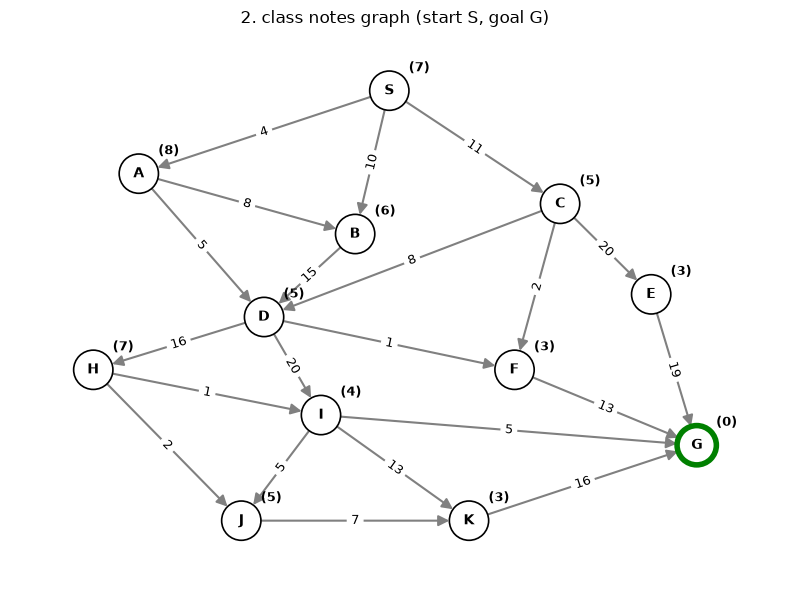

In [4]:
notes_graph = make_directed([
    ("S", "A", 4), ("S", "B", 10), ("S", "C", 11),
    ("A", "B", 8), ("A", "D", 5), ("B", "D", 15),
    ("C", "D", 8), ("C", "F", 2), ("C", "E", 20),
    ("D", "H", 16), ("D", "I", 20), ("D", "F", 1),
    ("E", "G", 19), ("F", "G", 13),
    ("H", "I", 1), ("H", "J", 2),
    ("I", "J", 5), ("I", "K", 13), ("I", "G", 5),
    ("J", "K", 7), ("K", "G", 16),
])

# The heuristic values
notes_h = {"S": 7, "A": 8, "B": 6, "C": 5, "D": 5, "E": 3, "F": 3, "H": 7, "I": 4, "J": 5, "K": 3, "G": 0}

notes_pos = {
    "S": (4.6, 9.5), "A": (2.4, 8.4), "B": (4.3, 7.6), "C": (6.1, 8.0), "D": (3.5, 6.5), "E": (6.9, 6.8),
    "F": (5.7, 5.8), "H": (2.0, 5.8), "I": (4.0, 5.2), "G": (7.3, 4.8), "J": (3.3, 3.8), "K": (5.3, 3.8),
}

draw_graph(notes_graph, notes_pos, h=notes_h, goals=["G"], directed=True,
           title="2. class notes graph (start S, goal G)", figsize=(8, 6));

---

# 2. Greedy Best-First Search

## 2.1 The idea

Greedy search always selects the frontier node with the **lowest heuristic value** $h(n)$ for expansion - the
state it *believes* is nearest to a goal. It completely ignores the cost already paid to get there.

**Frontier**: a priority queue, exactly like UCS, but the priority is $h(n)$ instead of the path cost $g(n)$.

 The `parent` dictionary works as the visited set. Without the parent dict, the algorithm can enter an infinite loop.

Like in UCS last week, the heap holds `(priority, node)` tuples, so when two nodes have the same $h$, the one whose
name comes first alphabetically is expanded first.

Keep in mind that greedy can jump around the state space, it doesn't necessarily need to visit a node adjacent to the current node, it gets the node with the lowest heuristic value in all of the visited nodes, not only the current neighbors.

In [5]:
def greedy(graph, h, start, goal):
    frontier = [(h[start], start)]                   # (h, node) - heap sorts by h, ties by node name
    parent = {start: None}
    expanded = [] # Only for visualization purposes, not used in the algorithm

    while frontier:
        _, node = heapq.heappop(frontier)
        if node == goal:
            path = reconstruct_path(parent, goal)
            return path, path_cost(graph, path), expanded, set(parent)

        expanded.append(node)

        for neighbour, _ in graph[node]:
            if neighbour not in parent:
                parent[neighbour] = node
                heapq.heappush(frontier, (h[neighbour], neighbour))

    return None, float("inf"), expanded, set(parent)

Greedy: path: S -> B -> D -> E -> F -> G (cost 13) | expanded: S B D E F


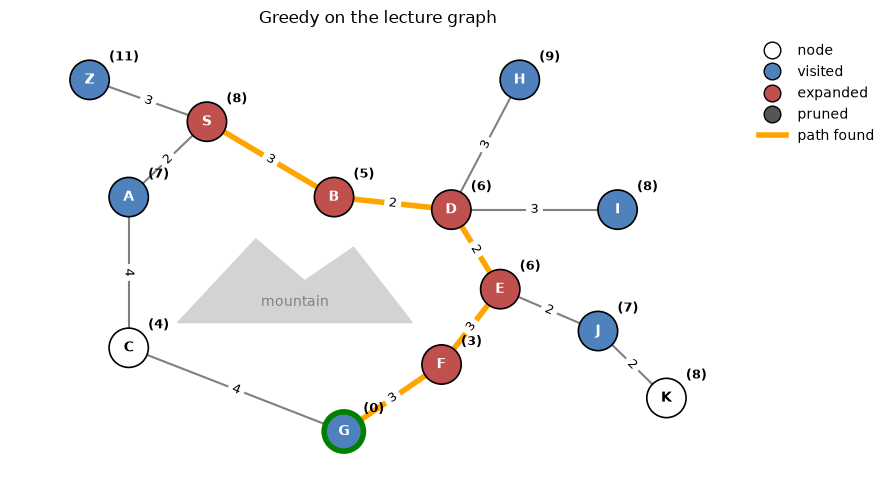

In [6]:
_path, _cost, _expanded, _visited = greedy(lecture_graph, lecture_h, "S", "G")
print("Greedy:", format_result(_path, _cost, _expanded))

add_mountain(draw_graph(lecture_graph, lecture_pos, h=lecture_h, path=_path, expanded=_expanded,
                        visited=_visited, goals=["G"], title="Greedy on the lecture graph"));

Greedy goes **S - B - D - E - F - G with cost 13**: B has $h = 5$, which looks much better than A with $h = 7$. The path S - A - C - G costs only **10**. Greedy reaches
the goal, but not along the cheapest path.

On the class notes graph the same thing happens:

Greedy: path: S -> C -> E -> G (cost 50) | expanded: S C E


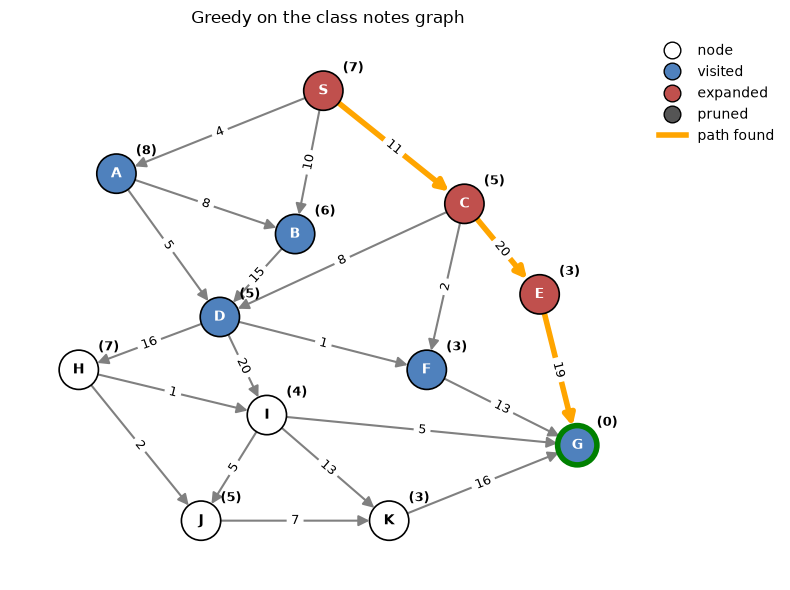

In [7]:
_path, _cost, _expanded, _visited = greedy(notes_graph, notes_h, "S", "G")
print("Greedy:", format_result(_path, _cost, _expanded))

draw_graph(notes_graph, notes_pos, h=notes_h, path=_path, expanded=_expanded, visited=_visited, goals=["G"],
           directed=True, title="Greedy on the class notes graph", figsize=(8, 6));

Greedy reaches G via **S - C - E - G with cost 50**, even though **S - A - D - F - G costs only 23**: it never
looks at the cost already paid.

It gets even worse. After expanding C, E and F both have $h = 3$, so the choice between them is a tie. E wins only
because it comes first alphabetically. Had the tie gone to F, greedy would have gone S - C - F - G and paid **26**,
which is still not optimal but almost half the cost. So the result depends on an arbitrary detail of the
implementation. Greedy search generally acts fairly unpredictably: it can
range from going straight to a goal to acting like a badly-guided DFS that explores all the wrong areas, and it all depends on how good our heuristic is.

## 2.2 Properties of Greedy

- **Complete? No in general**
    - **Tree search: No**, it can get stuck in loops.
    - **Graph search in infinite state spaces: No**, it can follow a path of ever-decreasing $h$ that never reaches the goal.
    - **Graph search in finite state spaces: Yes**
- **Optimal? No** - as we just saw twice.
- **Time? $O(b^m)$**
    - A bad heuristic can lead us to explore every node($O(b^m)$ in the worst case), a good heuristic can give a dramatic
      improvement, and with a perfect heuristic, greedy walks straight to the goal.
- **Space? $O(b^m)$** - keeps all nodes in the frontier.
- **Data structure: priority queue**, sorted by $h(n)$

---

# 3. Beam Search

## 3.1 The idea

**Beam Search = greedy best-first search with priority queue limit $l$**, i.e. it keeps only the best $l$ nodes in the
queue. The number $l$ is called the **beam width**.

Every time the frontier grows beyond $l$ nodes, the worst ones (highest $h$) are **thrown away forever** -
there is no going back to them. This is what makes beam search cheap in memory, and also what makes it
incomplete - the goal can be thrown away (also called "pruned").

In [8]:
def beam_search(graph, h, start, goal, width):
    frontier = [(h[start], start)]
    parent = {start: None}
    expanded = [] # Only for visualization purposes, not used in the algorithm
    pruned = set() # Only for visualization purposes, not used in the algorithm

    while frontier:
        _, node = heapq.heappop(frontier)
        if node == goal:
            path = reconstruct_path(parent, goal)
            return path, path_cost(graph, path), expanded, set(parent) - pruned, pruned

        expanded.append(node)

        for neighbour, _ in graph[node]:
            if neighbour not in parent: # pruned nodes stay in 'parent' and they are never added again
                parent[neighbour] = node
                heapq.heappush(frontier, (h[neighbour], neighbour))

        if len(frontier) > width: # the only addition to greedy search
            frontier.sort() # sort by heuristic, lowest h first, a sorted list is also a valid heap
            for _, node in frontier[width:]:
                pruned.add(node)
            frontier = frontier[:width]

    return None, float("inf"), expanded, set(parent) - pruned, pruned

Beam, l = 2: path: S -> B -> D -> E -> F -> G (cost 13) | expanded: S B D E F
pruned: ['H', 'I', 'J', 'Z']


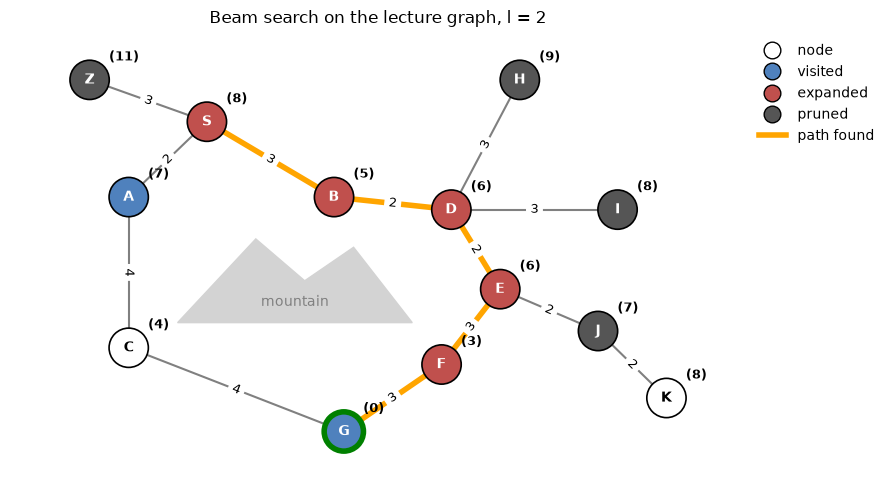

In [9]:
_path, _cost, _expanded, _visited, _pruned = beam_search(lecture_graph, lecture_h, "S", "G", width=2)
print("Beam, l = 2:", format_result(_path, _cost, _expanded))
print("pruned:", sorted(_pruned))

add_mountain(draw_graph(lecture_graph, lecture_pos, h=lecture_h, path=_path, expanded=_expanded,
                        visited=_visited, pruned=_pruned, goals=["G"],
                        title="Beam search on the lecture graph, l = 2"));

With $l = 2$:

1. expand S → frontier B(5), A(7), Z(11) → **Z is pruned**
2. expand B → frontier D(6), A(7)
3. expand D → frontier E(6), A(7), I(8), H(9) → **I and H are pruned**
4. expand E → frontier F(3), A(7), J(7) → **J is pruned** (A and J are tied, A comes first alphabetically)
5. expand F → frontier G(0), A(7) → G is popped, done

K is never even generated - the only way to it goes through J, which was pruned. On this graph beam search finds
the same path as greedy, with a frontier of at most 2 nodes instead of 5.

Here the beam did not hurt. Now a case where it does: we search for K, while still using the heuristic for G,
so K and the way to it look bad and get pruned:

In [10]:
for _width in (1, 2, 3):
    _path, _, _, _, _pruned = beam_search(lecture_graph, lecture_h, "S", "K", width=_width)
    print(f"goal K, l = {_width}: Path = {_path}, Pruned = {sorted(_pruned)}")

goal K, l = 1: Path = None, Pruned = ['A', 'H', 'I', 'J', 'Z']
goal K, l = 2: Path = None, Pruned = ['H', 'I', 'J', 'Z']
goal K, l = 3: Path = ['S', 'B', 'D', 'E', 'J', 'K'], Pruned = ['H', 'I', 'Z']


K exists and is reachable, but beam search with a small width throws away the only branch leading to it,
and then has nowhere to go back to. A wider beam keeps more alternatives alive and eventually finds it.

## 3.2 Properties of Beam Search

- **Complete? No** - the goal (or the only way to it) can be pruned away.
- **Optimal? No**
- **Time? $O(b \cdot m \cdot l)$** - linear time. At every level the algorithm does the following:
    - **Expansion**: it only expands the $l$ nodes kept from the previous level.
    - **Generation of successors**: each of the $l$ nodes generates $b$ successors, so $l \cdot b$ new candidates per level.
    - **Heuristic evaluation**: it computes $h$ for all $l \cdot b$ candidates - $O(l \cdot b)$ time.
    - **Pruning (selection)**: it selects the best $l$ out of the $l \cdot b$ candidates. Sorting would take
      $O(l b \log(l b))$. This step is usually treated as minor
      compared to the expansion cost, since we assume l and b are small numbers.
    - Repeated for at most $m$ levels: $O(m \cdot l \cdot b)$.
- **Space? $O(b \cdot l)$** - linear space: at most $l$ nodes plus their $b$ children each.
- **Data structure: limited priority queue** (size $l$, sorted by $h(n)$)

---

# 4. Hill Climbing

## 4.1 The idea

**Hill Climbing = greedy best-first search with queue limit $l = 1$**, i.e. it keeps only the best node.
In other words, it is beam search with a beam of width 1. After each expansion only the single best child
survives; everything else is discarded, and there is no backtracking.

> The name comes from optimization: we want to reach the highest point (the best value of an objective function),
> and we always step to the best neighbour. It is also called **gradient ascent/descent** when the state space is
> continuous (the algorithm that is used to train neural networks).

It is also possible to modify Hill Climbing to stop if all neighbors have a higher heuristic - in our implementation it will always continue, even if the neighbor with the smallest heuristic has a higher heuristic than the current node.

In [11]:
def hill_climbing(graph, h, start, goal):
    return beam_search(graph, h, start, goal, width=1)

Hill climbing:   path: S -> B -> D -> E -> F -> G (cost 13) | expanded: S B D E F


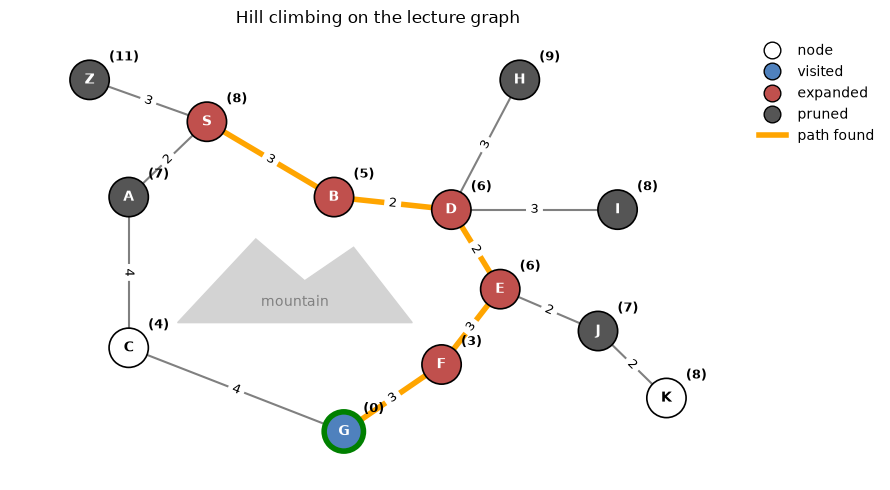

In [12]:
_path, _cost, _expanded, _visited, _pruned = hill_climbing(lecture_graph, lecture_h, "S", "G")
print("Hill climbing:  ", format_result(_path, _cost, _expanded))

add_mountain(draw_graph(lecture_graph, lecture_pos, h=lecture_h, path=_path, expanded=_expanded,
                        visited=_visited, pruned=_pruned, goals=["G"], title="Hill climbing on the lecture graph"));

We reach G (S - B - D - E - F - G, cost 13). Note the step B(5) → D(6): it moved to a
  *worse* node, simply because D was the only child left. It behaves like greedy search that is never allowed to backtrack.

## 4.2 Properties of Hill Climbing

- **Complete? No** - it can follow a branch that never
  leads to the goal, without any way back.
- **Optimal? No**
- **Time? $O(b \cdot m)$** - beam search's $O(bml)$ with $l = 1$
- **Space? $O(b)$** - beam search's $O(bl)$ with $l = 1$
- **Data structure: "limited priority queue" of size 1** - in quotes, because a "queue" that holds one
  element is just a variable.

---

# 5. Heuristics

So far any function that estimates the remaining cost was good enough. Before A*, let us look at the properties a
heuristic can have, and how to compare two heuristics.

## 5.1 Admissible heuristics

A heuristic is **admissible** if it **never overestimates** the true cost: $h(n) \le h^*(n)$ for every $n$, where
$h^*(n)$ is the true cost of the cheapest path from $n$ to a goal. (We also require $h(n) \ge 0$, so $h(G) = 0$ for
any goal $G$.)

- E.g. $h_{SLD}(n)$, the straight-line distance, never overestimates the actual road distance.
- $h(n) = 0$ for all $n$ is admissible, but useless - it gives no guidance at all.

Admissible heuristics are often constructed from the exact solution of a **relaxed problem** - a
problem where some constraints on the actions are removed. Removing constraints can only make the optimal solution
cheaper (or equal), so:

$$h(n) = \text{optimal cost in the relaxed problem} \le \text{optimal cost in the original problem} = h^*(n)$$

 The cost of an optimal solution
to a relaxed problem is an admissible heuristic for the original problem: every solution of the original problem is
also a solution of the relaxed one, so the relaxed optimum can only be cheaper or equal.

The original rule of the 8-puzzle is: *a tile can move from square A to square B if A is adjacent to B and B is
blank*. Dropping parts of it gives our two heuristics:

- Relax it so that **a tile can move anywhere** (drop both conditions) → each misplaced tile needs exactly one move
  → the optimal cost is $h_1(n)$.
- Relax it so that **a tile can move to any adjacent square**, blank or not (drop "B is blank") → each tile walks
  straight to its place → the optimal cost is $h_2(n)$.

> Key point: the optimal solution cost of a relaxed problem is no greater than the optimal solution cost of the real
> problem. In general, most natural admissible heuristics tend to be consistent, especially if they come from
> relaxed problems.

## 5.2 Consistent heuristics

A heuristic is **consistent** if for every node $n$ and every successor $n'$:

$$h(n) \le c(n, n') + h(n')$$

It is a triangle inequality: the estimate from $n$ is never bigger than the cost of the step to $n'$ plus the
estimate from $n'$.


Rearranged, $h(n) - h(n') \le c(n, n')$: the heuristic can **drop by at most the step cost**.

**consistent $\implies$ admissible**

**admissible $\not\implies$ consistent**

## 5.3 Two heuristics for the 8-puzzle

The 8-puzzle: a 3×3 board with tiles 1 - 8 and one blank. A move slides a tile adjacent to the blank into the
blank (cost 1). The goal is to arrange the tiles in order.

- $h_1(n)$ = number of misplaced tiles (**Hamming distance**)
- $h_2(n)$ = total **Manhattan distance**, i.e. for one tile at $(x, y)$ with goal position $(x', y')$:
  $\text{tileDist} = |x - x'| + |y - y'|$. For all tiles:

$$h_2(n) = \sum_{\text{all tiles}} |\text{current row} - \text{goal row}| + |\text{current column} - \text{goal column}|$$

The blank is **not** a tile, so it is not counted in either heuristic.

tile 1: at (row 2, col 2), goal (row 0, col 0) -> misplaced 1, distance 4
tile 2: at (row 0, col 1), goal (row 0, col 1) -> misplaced 0, distance 0
tile 3: at (row 2, col 1), goal (row 0, col 2) -> misplaced 1, distance 3
tile 4: at (row 0, col 2), goal (row 1, col 0) -> misplaced 1, distance 3
tile 5: at (row 1, col 0), goal (row 1, col 1) -> misplaced 1, distance 1
tile 6: at (row 1, col 2), goal (row 1, col 2) -> misplaced 0, distance 0
tile 7: at (row 0, col 0), goal (row 2, col 0) -> misplaced 1, distance 2
tile 8: at (row 2, col 0), goal (row 2, col 1) -> misplaced 1, distance 1

h1(S) = 1 + 0 + 1 + 1 + 1 + 0 + 1 + 1 = 6
h2(S) = 4 + 0 + 3 + 3 + 1 + 0 + 2 + 1 = 14


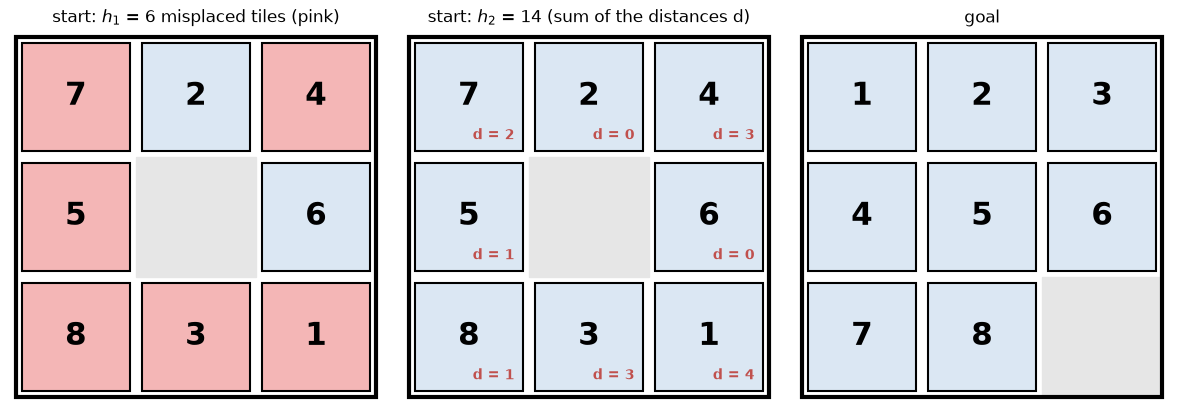

In [13]:
puzzle_start = (7, 2, 4,
                5, 0, 6,
                8, 3, 1)
puzzle_goal = (1, 2, 3,
               4, 5, 6,
               7, 8, 0)          # 0 is the blank


def hamming(state, goal):
    return sum(1 for tile, target in zip(state, goal) if tile != 0 and tile != target)


def manhattan(state, goal):
    total = 0
    for index, tile in enumerate(state):
        if tile != 0:
            goal_index = goal.index(tile)
            total += abs(index // 3 - goal_index // 3) + abs(index % 3 - goal_index % 3)
    return total


_h1_terms, _h2_terms = [], []
for _tile in range(1, 9):
    _i, _j = puzzle_start.index(_tile), puzzle_goal.index(_tile)
    _h1_terms.append(int(_i != _j))
    _h2_terms.append(abs(_i // 3 - _j // 3) + abs(_i % 3 - _j % 3))
    print(f"tile {_tile}: at (row {_i // 3}, col {_i % 3}), goal (row {_j // 3}, col {_j % 3}) -> "
          f"misplaced {_h1_terms[-1]}, distance {_h2_terms[-1]}")

print()
print("h1(S) =", " + ".join(map(str, _h1_terms)), "=", hamming(puzzle_start, puzzle_goal))
print("h2(S) =", " + ".join(map(str, _h2_terms)), "=", manhattan(puzzle_start, puzzle_goal))

_misplaced = {tile for tile, misplaced in zip(range(1, 9), _h1_terms) if misplaced}
_distances = {tile: f"d = {distance}" for tile, distance in zip(range(1, 9), _h2_terms)}
_fig, _axes = plt.subplots(1, 3, figsize=(12, 4.2))
draw_puzzle(_axes[0], puzzle_start, f"start: $h_1$ = {hamming(puzzle_start, puzzle_goal)} misplaced tiles (pink)",
            highlighted=_misplaced)
draw_puzzle(_axes[1], puzzle_start, f"start: $h_2$ = {manhattan(puzzle_start, puzzle_goal)} "
            f"(sum of the distances d)", corner_labels=_distances)
draw_puzzle(_axes[2], puzzle_goal, "goal")
_fig.tight_layout(pad=1.5)

$h_1(S) = 1 + 0 + 1 + 1 + 1 + 0 + 1 + 1 = 6$ and $h_2(S) = 4 + 0 + 3 + 3 + 1 + 0 + 2 + 1 = 14$. For example
tile 1 is in the bottom-right corner (row 2, column 2) and belongs in the top-left (row 0, column 0):
$|2 - 0| + |2 - 0| = 4$. (The true optimal solution of this start state takes 26 moves - both heuristics
underestimate it, as they must.)

**Both the Hamming and the Manhattan heuristics are admissible and consistent.**

## 5.4 Dominance

For two admissible heuristics $h_1(n)$ and $h_2(n)$, if $h_2(n) \ge h_1(n)$ for all $n$, then $h_2$ **dominates** $h_1$ and is better for search - this is intuitive, because $h_2(n)$ is closer than $h_1(n)$ to the real $h^*(n)$.

Every tile that is misplaced is at least one square away, so the Manhattan distance always dominates the Hamming distance.

Given any admissible heuristics $h_a$ and $h_b$, $h(n) = \max(h_a(n), h_b(n))$ is also admissible and
dominates both $h_a$ and $h_b$. (Both are $\le h^*$, so their maximum is too.) If you have several heuristics and none dominates the others, take the maximum.

---

# 6. A* Search

## 6.1 The idea

**Idea**: Combine UCS (which looks at the cost already paid)
with greedy (which looks at the estimated cost still to pay). It is basically UCS that is guided by the available heuristic.

Evaluation function $f(n) = g(n) + h(n)$:

- $g(n)$ = cost so far to reach $n$ (exact, like in UCS)
- $h(n)$ = estimated cost from $n$ to the goal (the heuristic, like in greedy)
- $f(n)$ = **estimated total cost of the cheapest path from start to goal that goes through $n$**


A* is only guaranteed to find the optimal path with an **admissible heuristic**.

Two special cases show where A* sits:

- If $h(n) = 0$ for all $n$, then $f = g$, and  **A\* becomes UCS**
- If we ignore $g$ and say $g(n)=0$ for all $n$, then $f = h$ and **A\* becomes greedy best first search**

## 6.2 The algorithm

The code is UCS from last week, with the priority changed from $g$ to $g + h$.

In [14]:
def a_star(graph, h, start, goal):
    frontier = [(h[start], start)]     # (f, node), where f = g + h
    best_g = {start: 0}                # cheapest known cost to every visited node
    parent = {start: None}

    expanded = [] # Only for visualization purposes, not used in the algorithm

    while frontier:
        f, node = heapq.heappop(frontier)        # f = g + h
        g = best_g[node]
        if f > g + h[node]:                      # old entry in the priority queue, a more expensive copy - skip it
            continue
        if node == goal:                         # goal test on EXPANSION, like in UCS
            return reconstruct_path(parent, goal), g, expanded, set(best_g)

        expanded.append(node)

        for neighbour, step_cost in graph[node]:
            new_g = g + step_cost
            if new_g < best_g.get(neighbour, float("inf")):  # relaxation
                best_g[neighbour] = new_g
                parent[neighbour] = node
                heapq.heappush(frontier, (new_g + h[neighbour], neighbour))

    return None, float("inf"), expanded, set(best_g)

A*: path: S -> A -> C -> G (cost 10) | expanded: S B A C


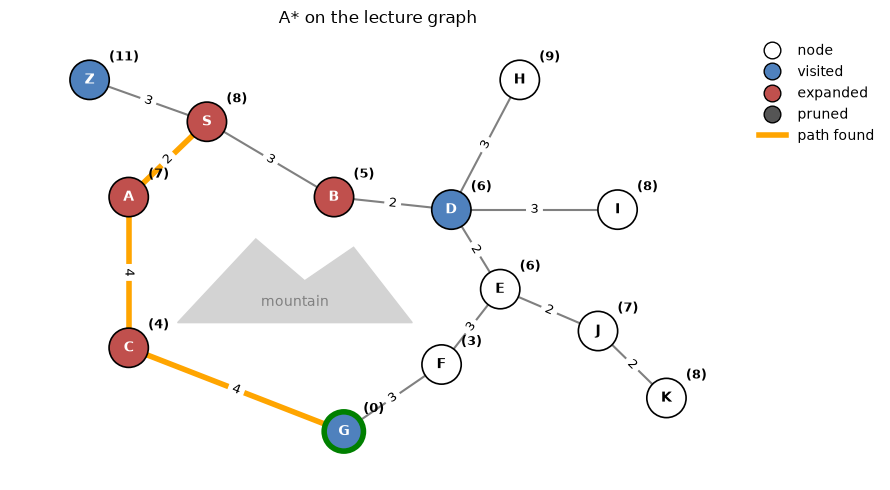

In [15]:
_path, astar_lecture_cost, astar_lecture_expanded, _visited = a_star(lecture_graph, lecture_h, "S", "G")
print("A*:", format_result(_path, astar_lecture_cost, astar_lecture_expanded))

add_mountain(draw_graph(lecture_graph, lecture_pos, h=lecture_h, path=_path, expanded=astar_lecture_expanded,
                        visited=_visited, goals=["G"], title="A* on the lecture graph"));

A* finds the optimal path **S - A - C - G with cost 10**. Step by step, with $f = g + h$:

1. expand S ($0 + 8 = 8$) → frontier B ($3 + 5 = 8$), A ($2 + 7 = 9$), Z ($3 + 11 = 14$)
2. expand B (8) → adds D ($5 + 6 = 11$)
3. expand A (9) → adds C ($6 + 4 = 10$)
4. expand C (10) → adds G ($10 + 0 = 10$)
5. pop G (10) → done

## 6.3 Properties of A*

- **Complete? Yes**
    - But we need every step cost to be $\ge \varepsilon > 0$, like UCS.
- **Optimal?**
    - **For tree search: Yes**, if the heuristic is admissible, else not guaranteed.
    - **For graph search: Yes**, if the heuristic is consistent (thus also admissible), else not guaranteed.
- **Time? $O(b^d)$**
    - With the perfect heuristic $h = h^*$, A* only expands nodes on an optimal path, which is linear time.
    - With $h = 0$, A* becomes UCS.
    - Everything in between depends on how wrong $h$ is - if the heuristic is totally wrong, we expand every node in the graph.
- **Space? $O(b^d)$** - keeps all nodes in memory. This is usually the real problem
  with A*, it runs out of memory long before it runs out of time.
- **Data structure: priority queue** (by $f(n) = g(n) + h(n)$)
---

# 7. Iterative Deepening A* (IDA*)

The weak point of A* is memory: $O(b^d)$ nodes can be kept in memory.

**IDA\* = combination of A\* and iterative deepening search**, i.e. it uses the A* evaluation function
$f(n) = g(n) + h(n)$ as a **threshold** and runs a depth-first search (like DLS, but cut off by $f$ instead of depth).

- The first threshold is $f(\text{start}) = h(\text{start})$.
- Each iteration is a depth-first search that **prunes every node with $f(n) > \text{threshold}$**.
- The next threshold is the **smallest $f$-value that was pruned** in the previous iteration. This way no
  threshold value that could matter is skipped, and every iteration explores at least one new node.
- Stop when the goal is found, or when nothing was pruned (the whole space was searched: there is no solution).

### Properties of IDA*

- **Complete? Yes** (same conditions as A*)
- **Optimal? Yes** with an admissible heuristic - it never expands a node with $f > C^*$ before it has tried all
  thresholds below $C^*$.
- **Time? $O(b^d)$** - like IDS, the repeated work in earlier iterations is small compared to the last one.
- **Space? $O(bd)$** - it is a DFS underneath, so it only stores the current path. This is the whole point.
- **Data structure: stack**

Because it does not keep a closed set, IDA* can generate the same state many times through different paths. We only
check for cycles along the current path, like in DLS.

In [16]:
def ida_star(graph, h, start, goal):
    path = [start]

    # returns True, or the smallest f that was cut off (the candidate for the next threshold)
    def search(node, g, threshold):
        f = g + h[node]
        if f > threshold:                             # cut off
            return f
        if node == goal:
            return True
        smallest = float("inf")
        for neighbour, step_cost in graph[node]:
            if neighbour in path:                     # avoid cycles along the current path
                continue
            path.append(neighbour)
            result = search(neighbour, g + step_cost, threshold)
            if result is True:
                return True
            smallest = min(smallest, result)
            path.pop()
        return smallest

    threshold = h[start]
    while True:
        threshold = search(start, 0, threshold)
        if threshold is True:
            return list(path)
        if threshold == float("inf"):  # nothing was cut off, so there is no solution
            return None

---

# 8. Summary of the algorithms

| Criterion | Greedy | Beam Search | Hill Climbing | A* | IDA* |
|---|---|---|---|---|---|
| **Complete** | No* | No | No | Yes* | Yes |
| **Time** | $O(b^m)$ | $O(blm)$ | $O(bm)$ | $O(b^d)$ | $O(b^d)$ |
| **Space** | $O(b^m)$ | $O(bl)$ | $O(b)$ | $O(b^d)$ | $O(bd)$ |
| **Optimal** | No | No | No | Yes | Yes |
| **Data structure** | Priority Queue | Limited Priority Queue | "Limited Priority Queue" | Priority Queue | Stack |

- Greedy: \* complete in finite state spaces with graph search (repeated-state checking).
- A*: \* complete if every step cost is $\ge \varepsilon > 0$. Optimal with an admissible heuristic (tree search)
  or a consistent one (graph search).
- IDA*: optimal with an admissible heuristic.